In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import random
import matplotlib.colors as mcolors

In [2]:
documents = pd.read_csv("top_topic_documents.csv", index_col = 0)
documents.head()

,basename,year,topic,score
0,ra_10924_2016,2016,14,0.551755
1,ra_10923_2016,2016,3,0.405266
2,ra_10925_2017,2017,4,0.901010
3,ra_10926_2017,2017,11,0.659243
4,ra_10927_2017,2017,10,0.513400


In [3]:
topics = pd.read_csv("top_topics.csv", index_col=0)
print(f"total topics: {len(topics)}")
topics.head()

total topics: 20


,topic,word,prob,labels
0,0,product,0.026058,"marking, distributor, trademark, engine, manuf..."
1,1,education,0.038444,"readiness, learner, instructional material, li..."
2,2,campus,0.063781,"section asset real personal personnel, progres..."
3,3,barangay,0.069155,"san_antonio, sitio, alvarez_speaker_of_the_hou..."
4,4,grantee,0.042825,"extreme_emergency_or_calamity ntc issue, equiv..."


In [4]:
documents.query('year == 2016')

,basename,year,topic,score
0,ra_10924_2016,2016,14,0.551755
1,ra_10923_2016,2016,3,0.405266


In [5]:
df = pd.merge(documents, topics, on=['topic'], how='inner')
df

,basename,year,topic,score,word,prob,labels
0,ra_10924_2016,2016,14,0.551755,fund,0.020654,"equipment spare, equipment spare part, rent, s..."
1,ra_10923_2016,2016,3,0.405266,barangay,0.069155,"san_antonio, sitio, alvarez_speaker_of_the_hou..."
2,ra_10925_2017,2017,4,0.901010,grantee,0.042825,"extreme_emergency_or_calamity ntc issue, equiv..."
3,ra_10926_2017,2017,11,0.659243,grantee,0.055234,ntc not_unreasonably_withhold delay_the_grant ...
4,ra_10927_2017,2017,10,0.513400,person,0.035447,"affirmation, conspire, signatory, investigatio..."
...,...,...,...,...,...,...,...
990,ra_11929_2022,2022,6,0.802915,city,0.060811,code amend develop_plans_and_strategies approv...
991,ra_11930_2022,2022,10,0.345237,person,0.035447,"affirmation, conspire, signatory, investigatio..."
992,ra_11931_2022,2022,11,0.953956,grantee,0.055234,ntc not_unreasonably_withhold delay_the_grant ...
993,ra_11932_2022,2022,12,0.605405,national,0.021932,"serve unexpired, serve unexpired term, reading..."


[731, 639, 643, 843, 419, 169, 828, 728, 478, 208, 21, 562, 663, 704, 544, 487, 678, 161, 461, 582]


Text(0.5, 1.0, 'Topic Distribution for 2016-2022')

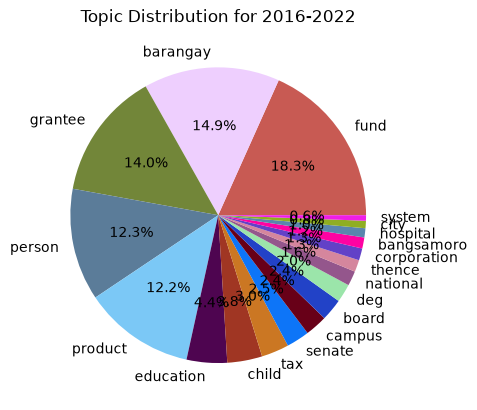

In [ ]:
topic_labels = df['word'].unique()
topic_colors = {}
i = 0
color_list = list(mcolors.XKCD_COLORS)
# random_colors = random.sample(range(1, len(color_list)), len(topics))
random_colors = [731, 639, 643, 843, 419, 169, 828, 728, 478, 208, 21, 562, 663, 704, 544, 487, 678, 161, 461, 582]
print(random_colors)
for l in topic_labels:
    topic_colors[l] = color_list[random_colors[i]]
    i = i + 1
counts = df['word'].value_counts()
fig, ax = plt.subplots(1, 1)
labels = df['word'].unique()
ax.pie(counts, labels=labels, colors=[topic_colors[key] for key in labels], autopct='%1.1f%%')
ax.set_title(f'Topic Distribution for 2016-2022')

Sample for year: 2016
----------
title: ra_10924_2016; topic: 14(fund); auto-labels: equipment spare, equipment spare part, rent, spare, spare part
title: ra_10923_2016; topic: 3(barangay); auto-labels: san_antonio, sitio, alvarez_speaker_of_the_house_of_representatives this_act originated_in_the_house_of_representatives, pantaleon_d alvarez_speaker_of_the_house_of_representatives this_act originated_in_the_house_of_representatives, pantaleon_d alvarez_speaker_of_the_house_of_representatives this_act originated_in_the_house_of_representatives was_passed_by_the_house_of_representatives


Sample for year: 2017
----------
title: ra_10943_2017; topic: 3(barangay); auto-labels: san_antonio, sitio, alvarez_speaker_of_the_house_of_representatives this_act originated_in_the_house_of_representatives, pantaleon_d alvarez_speaker_of_the_house_of_representatives this_act originated_in_the_house_of_representatives, pantaleon_d alvarez_speaker_of_the_house_of_representatives this_act originated_in_t

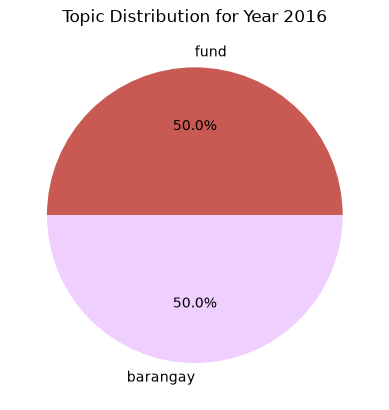

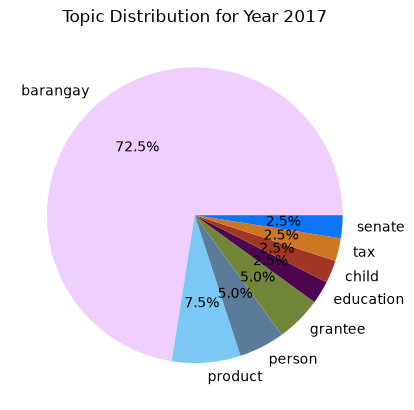

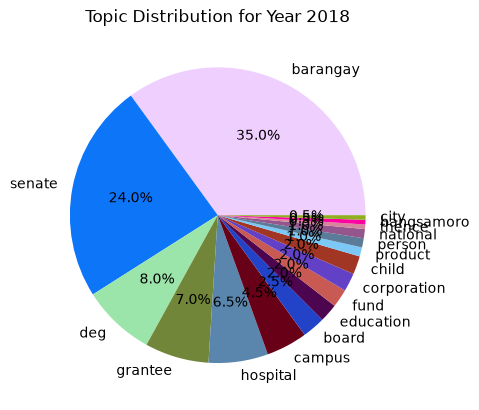

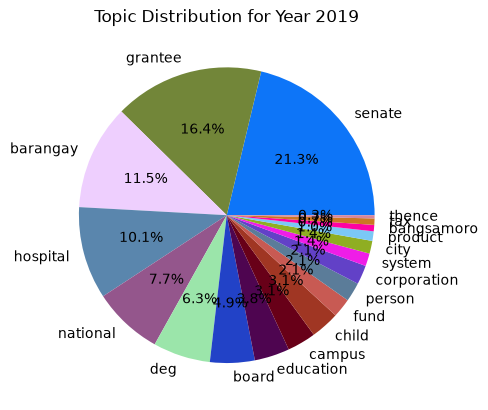

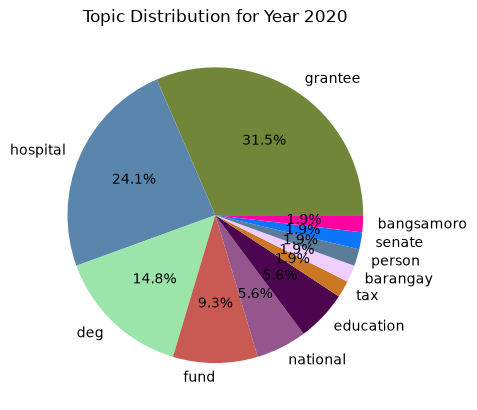

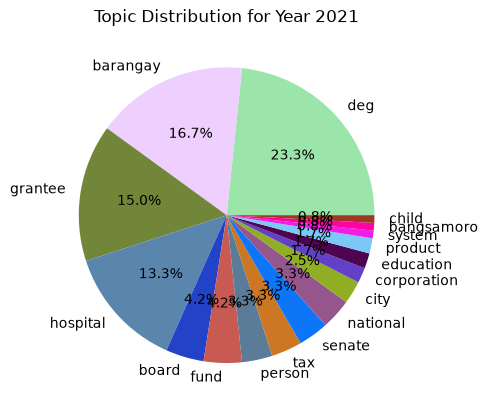

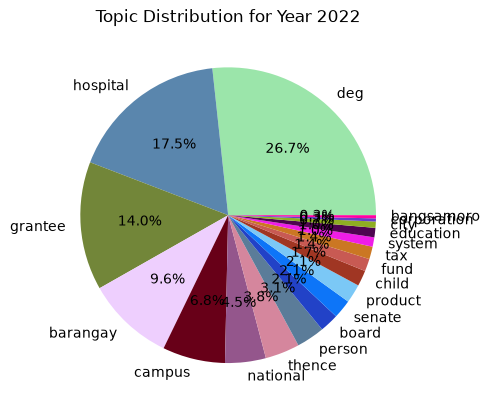

In [7]:
for year in df['year'].unique():
    period = df.query(f'year == {year}')
    counts = period['word'].value_counts()
    labels = counts.index.tolist()
    x = counts.values.tolist()
    fig, ax = plt.subplots(1, 1)
    ax.pie(counts, labels=labels, colors=[topic_colors[key] for key in labels], autopct='%1.1f%%')
    ax.set_title(f'Topic Distribution for Year {year}')

    n_sample = 5 if len(period) > 5 else len(period)
    samp = period.sample(n_sample)
    print(f"Sample for year: {year}\n----------")
    for _, row in samp.iterrows():
        print(f"title: {row['basename']}; topic: {row['topic']}({row['word']}); auto-labels: {row['labels']}")
    print("\n")
    # counts = period['word'].value_counts()
    # counts.plot(kind='pie', autopct='%1.1f%%')
    # plt.title(f'Topic Distribution for Year {year}')
    # plt.show()


In [8]:
# understanding what "senate" topic means

year = 2018
period = df.query(f'year == {year} and word == "senate"')
n_sample = 5 if len(period) > 5 else len(period)
samp = period.sample(n_sample)
print(f"Sample for year {year} with topic 'senate' \n----------")
for _, row in samp.iterrows():
    print(f"title: {row['basename']}")
print("\n")

# conclusion: generally declaring a holiday or "National ___ Day"

Sample for year 2018 with topic 'senate' 
----------
title: ra_11100_2018
title: ra_11136_2018
title: ra_11114_2018
title: ra_11120_2018
title: ra_11144_2018




In [9]:
# understanding what "national" topic means

year = 2019
period = df.query(f'year == {year} and word == "national"')
n_sample = 5 if len(period) > 5 else len(period)
samp = period.sample(n_sample)
print(f"Sample for year {year} with topic 'national' \n----------")
for _, row in samp.iterrows():
    print(f"title: {row['basename']}")
print("\n")

# conclusion: their contents don't seem to correlate much with one another.
# could be related to the phrase "This Act shall be known as the..."

Sample for year 2019 with topic 'national' 
----------
title: ra_11293_2019
title: ra_11363_2019
title: ra_11292_2019
title: ra_11364_2019
title: ra_11194_2019




In [13]:
# understanding what "deg" topic means

year = 2020
period = df.query(f'year == {year} and word == "deg"')
n_sample = 5 if len(period) > 5 else len(period)
samp = period.sample(n_sample)
print(f"Sample for year {year} with topic 'deg' \n----------")
for _, row in samp.iterrows():
    print(f"title: {row['basename']}")
print("\n")

# conclusion: generally establishment of offices

Sample for year 2020 with topic 'deg' 
----------
title: ra_11488_2020
title: ra_11489_2020
title: ra_11484_2020
title: ra_11490_2020
title: ra_11502_2020




In [11]:
# finding more "hospital" documents

year = 2019
period = df.query(f'year == {year} and word == "hospital"')
n_sample = 5 if len(period) > 5 else len(period)
samp = period.sample(n_sample)
print(f"Sample for year {year} with topic 'hospital' \n----------")
for _, row in samp.iterrows():
    print(f"title: {row['basename']}")
print("\n")

# conclusion: a few documents containing citizenship

Sample for year 2019 with topic 'hospital' 
----------
title: ra_11272_2019
title: ra_11391_2019
title: ra_11273_2019
title: ra_11289_2019
title: ra_11359_2019




In [ ]:
print("Total topic 4 (grantee) documents for 2020")
period = documents.query(f'year == 2020 and topic == 4')
print(len(period))

print("Total topic 4 (grantee) documents for 2019")
period = documents.query(f'year == 2019 and topic == 4')
print(len(period))

Total topic 4 (grantee) documents for 2020
11
Total topic 4 (grantee) documents for 2019
38
